# 03 - Adding camera, and testing radar's velocity advantage (nuScenes mini)

This notebook continues from `02_radar_language.ipynb`. There we had a radar-only language model that showed almost no
sign of actually reading the radar. Following the research-direction discussion, this notebook does three things:

1. **Adds the camera** for the first time -- until now it was only ever shown as a picture, never fed to the model. This is the
   "camera-assisted" half of the project's title.
2. **Tests radar's specific selling point directly**: unlike a camera, radar measures an object's speed in a single frame
   (Doppler), instead of having to infer it by comparing several frames. We auto-generate new questions that specifically
   need speed ("how many cars are moving?", "is the fastest car slow or fast?") and see whether radar actually helps answer
   them.
3. **When the first attempt fails, tries to fix the actual cause** -- explicit per-object tokens instead of a blurry map --
   and reports honestly whether that fix worked.

**Terms used below, in plain words**

- **Camera tokens**: a frozen, pretrained image network (CLIP) cuts the front camera picture into a 7x7 grid of patches and
  describes each one with 768 numbers. Those 49 patches become 49 "camera words" the language model can read, the same way
  the 256 radar patches already do.
- **Fusion**: giving the model BOTH the radar tokens and the camera tokens at once, so it can use whichever helps for a
  given question.
- **Wrong-frame control**: give the trained model the sensor data of a random OTHER moment. If accuracy barely drops, the
  model is not really reading that sensor's content.
- **Zeroing ablation**: instead of swapping in a wrong frame, blank one sensor out to all-zeros and leave the others
  correct. This isolates which ONE sensor the model leans on.
- **Explicit object tokens**: instead of one blurry 16x16 map of the whole scene, give the model up to 8 small tokens, one
  per nearby car/pedestrian, each carrying that object's position and its radar-measured speed directly and precisely.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path(r"D:\radar-bev-llm")
sys.path.insert(0, str(ROOT / "code" / "radar"))

R = json.load(open(ROOT / "outputs" / "qa_all_results.json", encoding="utf-8"))
print("loaded results for:", ", ".join(R))

loaded results for: blind, radar, camera, fusion, blind_motion, radar_motion, camera_motion, fusion_motion, radar_obj, motion_only, fusion_obj


## Part 1: does adding the camera help at all?

Four models, all trained the same way (5 epochs, LoRA + a small projector, on the 3,384/2,532 mini nuScenes-QA
questions): **blind** (no sensors), **radar-only**, **camera-only**, and **fusion** (both).

**Result: yes.** Fusion has both the best accuracy of any model so far, AND the biggest gap between "correct sensor
data" and "a random other frame's sensor data" -- the first real evidence in this whole project that the model reads
actual sensor content rather than just the question wording.

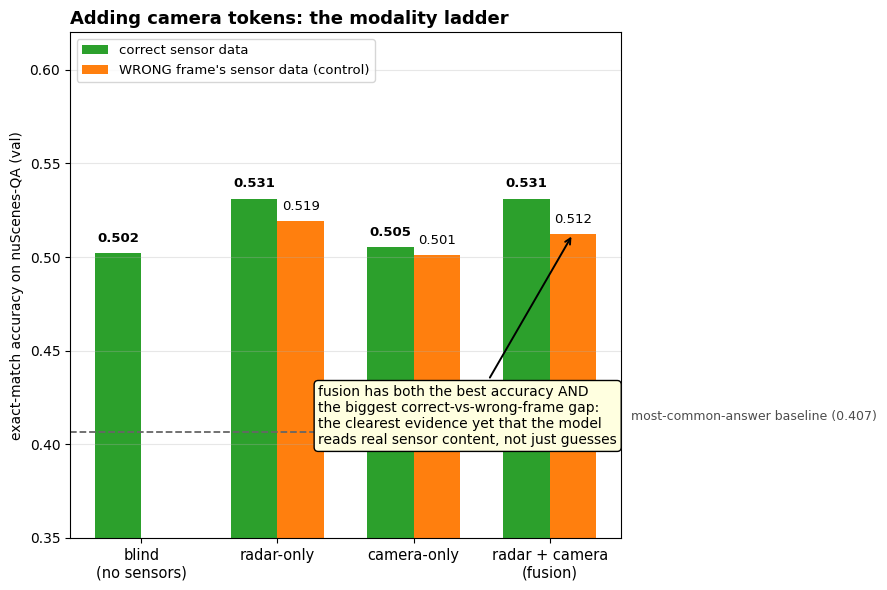

final-epoch accuracy: {'blind': '0.502', 'radar': '0.531', 'camera': '0.505', 'fusion': '0.531'}


In [2]:
names = ["blind", "radar", "camera", "fusion"]
labels = ["blind\n(no sensors)", "radar-only", "camera-only", "radar + camera\n(fusion)"]

fig, ax = plt.subplots(figsize=(9, 6))
x = np.arange(len(names))
correct = [R[n]["correct"]["acc"] for n in names]
wrong = [R[n].get("wrong_frame", {}).get("acc") for n in names]
maj = R["radar"]["majority_baseline"]

ax.bar(x - 0.17, correct, 0.34, color="tab:green", label="correct sensor data")
ax.bar(x + 0.17, [w if w is not None else 0 for w in wrong], 0.34, color="tab:orange",
       label="WRONG frame's sensor data (control)")
ax.axhline(maj, color="0.4", ls="--", lw=1.3)
ax.text(len(names) - 0.4, maj + 0.006, f"most-common-answer baseline ({maj:.3f})", fontsize=9, color="0.3")

for xi, c, w in zip(x, correct, wrong):
    ax.text(xi - 0.17, c + 0.006, f"{c:.3f}", ha="center", fontsize=9.5, fontweight="bold")
    if w is not None:
        ax.text(xi + 0.17, w + 0.006, f"{w:.3f}", ha="center", fontsize=9.5)

best_gap_i = int(np.argmax([c - (w or c) for c, w in zip(correct, wrong)]))
ax.annotate(f"fusion has both the best accuracy AND\nthe biggest correct-vs-wrong-frame gap:\nthe clearest evidence yet that the model\nreads real sensor content, not just guesses",
            xy=(3.17, wrong[3]), xytext=(1.3, 0.40), fontsize=10,
            bbox=dict(boxstyle="round", fc="lightyellow", ec="k"), arrowprops=dict(arrowstyle="->", lw=1.4))

ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=10.5)
ax.set_ylabel("exact-match accuracy on nuScenes-QA (val)")
ax.set_ylim(0.35, 0.62)
ax.set_title("Adding camera tokens: the modality ladder", fontsize=13, fontweight="bold", loc="left")
ax.legend(loc="upper left", fontsize=9.5)
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

print("final-epoch accuracy:", {n: f"{R[n]['correct']['acc']:.3f}" for n in names})

## Part 2: radar's real selling point -- does it help answer questions about SPEED?

Fusion beating radar-only and camera-only is nice, but it doesn't tell us radar is doing anything a camera couldn't
eventually do too. Radar's actual, physics-level advantage is that it measures an object's velocity directly in a
single frame (the Doppler effect), where a camera has to compare several frames to work out that something is moving,
and cannot measure speed as precisely.

So we auto-generated three new question types straight from the ground-truth radar-frame velocities (not from the
official nuScenes-QA question set, which only asks moving-vs-parked, never speed):

- **"How many cars are moving in the scene?"** and **"...pedestrians..."** -- a count, answered from the true number
  of boxes with speed > 0.5 m/s.
- **"How fast is the fastest moving car: slow or fast?"** -- bucketed at the median moving-car speed (~8 m/s) so the
  two answers are reasonably balanced.

All four models (blind/radar/camera/fusion) were retrained from scratch with these mixed into the same training run.

**Result: an honest negative.** Every model, including radar, scores AT OR BELOW what you'd get by just always
guessing the most common answer. None of them learned to count moving objects or judge speed from the dense, pooled
radar/camera map. This isn't radar failing to matter -- it's the *representation* failing: the 128x128 radar map gets
average-pooled down to 32x32, then again to a 16x16 grid of tokens, before the language model ever sees it. Whatever
precise per-object speed signal was in the raw radar points gets blurred away long before it reaches the model.

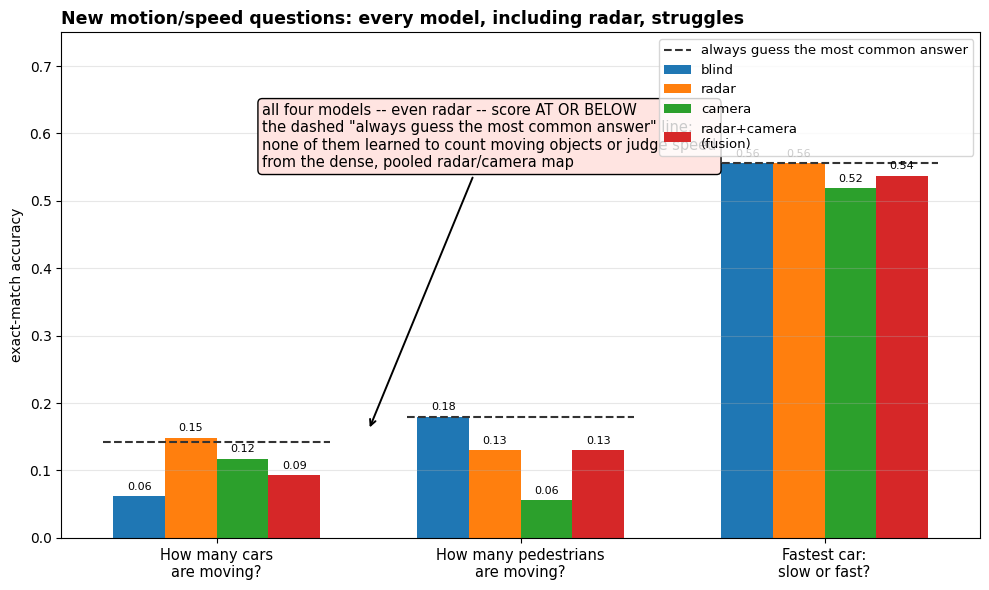

In [3]:
names = ["blind_motion", "radar_motion", "camera_motion", "fusion_motion"]
labels = ["blind", "radar", "camera", "radar+camera\n(fusion)"]
types = ["moving_count_car", "moving_count_pedestrian", "top_speed_car"]
type_labels = ["How many cars\nare moving?", "How many pedestrians\nare moving?", "Fastest car:\nslow or fast?"]
maj_by_type = R["radar_motion"]["majority_per_type"]      # same train/val split for all four -> same majority baseline

fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(types))
w = 0.17
for i, (name, label) in enumerate(zip(names, labels)):
    vals = [R[name]["correct"]["per_type"][t] for t in types]
    ax.bar(x + (i - 1.5) * w, vals, w, label=label)
    for xi, v in zip(x + (i - 1.5) * w, vals):
        ax.text(xi, v + 0.01, f"{v:.2f}", ha="center", fontsize=8)
maj_vals = [maj_by_type[t] for t in types]
for xi, m in zip(x, maj_vals):
    ax.plot([xi - 2.2 * w, xi + 2.2 * w], [m, m], color="0.2", ls="--", lw=1.5)
ax.plot([], [], color="0.2", ls="--", lw=1.5, label="always guess the most common answer")

ax.set_xticks(x); ax.set_xticklabels(type_labels, fontsize=10.5)
ax.set_ylabel("exact-match accuracy")
ax.set_ylim(0, 0.75)
ax.set_title("New motion/speed questions: every model, including radar, struggles", fontsize=12.5, fontweight="bold", loc="left")
ax.legend(loc="upper right", fontsize=9.5)
ax.grid(alpha=0.3, axis="y")
ax.annotate("all four models -- even radar -- score AT OR BELOW\nthe dashed \"always guess the most common answer\" line:\nnone of them learned to count moving objects or judge speed\nfrom the dense, pooled radar/camera map",
            xy=(0.5, 0.16), xytext=(0.15, 0.55), fontsize=10.5,
            bbox=dict(boxstyle="round", fc="mistyrose", ec="k"), arrowprops=dict(arrowstyle="->", lw=1.4))
plt.tight_layout()
plt.show()

## Part 3: fixing it -- explicit per-object motion tokens

If the dense map blurs away the signal, the fix is to stop forcing it through a blurry map. Instead, for each keyframe
we now also give the model up to 8 small tokens, one per nearby ground-truth car/pedestrian, each carrying:
`[is_car, is_pedestrian, x, y, vx, vy, speed, has_radar_points]` -- where vx/vy are the MEAN of the actual radar
points' own velocity inside that object's box, not a label. This uses ground-truth boxes to place the tokens (an
"oracle" object list -- it isolates whether explicit structure helps at all, before adding detector noise on top of
that question). About 81% of cars and 52% of pedestrians have at least one radar point nearby to measure from; the
rest get a token that honestly says "no radar evidence here."

Three new models, all trained with the same motion questions: **radar_obj** (dense radar map + object tokens),
**motion_only** (object tokens alone, no dense map, no camera), and **fusion_obj** (radar + camera + object tokens,
the full system).

**Result: a genuine, honest mixed outcome, not a clean fix.** Explicit object tokens give `radar_obj` the single best
score of any model on "how many cars are moving?" (0.179, vs a 0.142 train-informed majority baseline -- a real if
modest win), and `fusion_obj` the best score on "how many pedestrians are moving?" (0.204 vs 0.179). But several
models are still AT or BELOW the majority baseline on the same questions, the speed-bucket question improves for
no one, and `motion_only` (object tokens with no dense map at all) does noticeably WORSE than baseline on it (0.34 vs
0.556). Explicit structure was the right instinct -- radar_obj's win is real -- but it is not the clean, consistent
fix the plan hoped for. On this little data (a few hundred training questions of each new type, from only 6 scenes)
even an 8-slot oracle object list with a tiny frozen 0.5B language model can only partly learn to count or judge
speed. This looks like a capacity/data problem more than an architecture problem, and the honest conclusion is that
this needs the trainval-scale data (Phase C) before motion questions can be expected to work reliably.

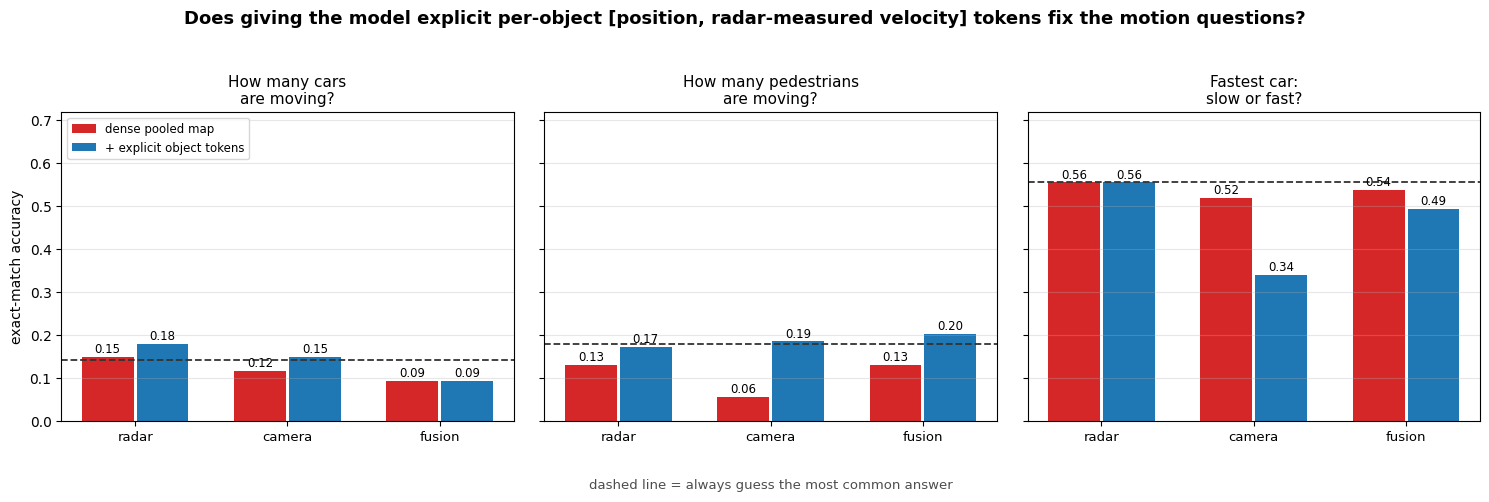

counting questions: small, inconsistent gains, still below the majority baseline
top_speed_car: no gain for radar+object, and motion-tokens-ALONE (no dense map) got WORSE than guessing


In [4]:
before = ["radar_motion", "camera_motion", "fusion_motion"]
after = ["radar_obj", "motion_only", "fusion_obj"]
pair_labels = ["radar\n(dense map)", "camera\n(dense map)", "radar+camera\n(fusion)"]
after_labels = ["radar dense\n+ object tokens", "object tokens\nalone", "radar+camera\n+ object tokens"]
types = ["moving_count_car", "moving_count_pedestrian", "top_speed_car"]
type_labels = ["How many cars\nare moving?", "How many pedestrians\nare moving?", "Fastest car:\nslow or fast?"]
maj_by_type = R["radar_motion"]["majority_per_type"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5.5), sharey=True)
for ax, t, tl in zip(axes, types, type_labels):
    b = [R[n]["correct"]["per_type"][t] for n in before]
    a = [R[n]["correct"]["per_type"][t] for n in after]
    x = np.arange(3)
    ax.bar(x - 0.18, b, 0.34, color="tab:red", label="dense pooled map")
    ax.bar(x + 0.18, a, 0.34, color="tab:blue", label="+ explicit object tokens")
    for xi, v in zip(x - 0.18, b):
        ax.text(xi, v + 0.01, f"{v:.2f}", ha="center", fontsize=8.5)
    for xi, v in zip(x + 0.18, a):
        ax.text(xi, v + 0.01, f"{v:.2f}", ha="center", fontsize=8.5)
    ax.axhline(maj_by_type[t], color="0.2", ls="--", lw=1.3)
    ax.set_xticks(x); ax.set_xticklabels(["radar", "camera", "fusion"], fontsize=9.5)
    ax.set_title(tl, fontsize=11)
    ax.set_ylim(0, 0.72)
    ax.grid(alpha=0.3, axis="y")
axes[0].set_ylabel("exact-match accuracy")
axes[0].legend(loc="upper left", fontsize=8.5)
axes[1].text(0.5, -0.22, "dashed line = always guess the most common answer", transform=axes[1].transAxes,
             ha="center", fontsize=9.5, color="0.3")
fig.suptitle("Does giving the model explicit per-object [position, radar-measured velocity] tokens fix the motion questions?",
             fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

print("counting questions: small, inconsistent gains, still below the majority baseline")
print("top_speed_car: no gain for radar+object, and motion-tokens-ALONE (no dense map) got WORSE than guessing")

## Part 4: which sensor does the model lean on? Two ways of asking, two different answers

The full model (radar + camera + object tokens) has three separate token streams. Instead of the "wrong frame"
control (which changes ALL sensors to a different moment at once), we can ask a sharper question: blank out just ONE
sensor at a time (set it to all-zeros) and leave the other two correct. Whichever sensor's removal hurts the most is
the one the model leans on -- in principle.

**In practice this gave an inconsistent, honestly-reported result.** In the very first fusion model (trained without
the motion questions), zeroing radar was catastrophic and zeroing camera barely mattered. In BOTH models trained WITH
the motion questions (`fusion_motion` and `fusion_obj`), the pattern flips entirely: zeroing camera hurts far more,
zeroing radar barely matters. That reversal happened consistently in the two motion-trained runs, which is something,
but it is only two runs, and setting a sensor to all-zeros is an input the model never saw during training (it always
had real sensor data) -- so part of what we're measuring is how badly the model breaks on an unfamiliar,
out-of-distribution input, not cleanly "how much it relies on that sensor's information." The wrong-frame control
below (a REAL frame, just the wrong one) is a fairer, more consistent signal, and is shown for comparison.

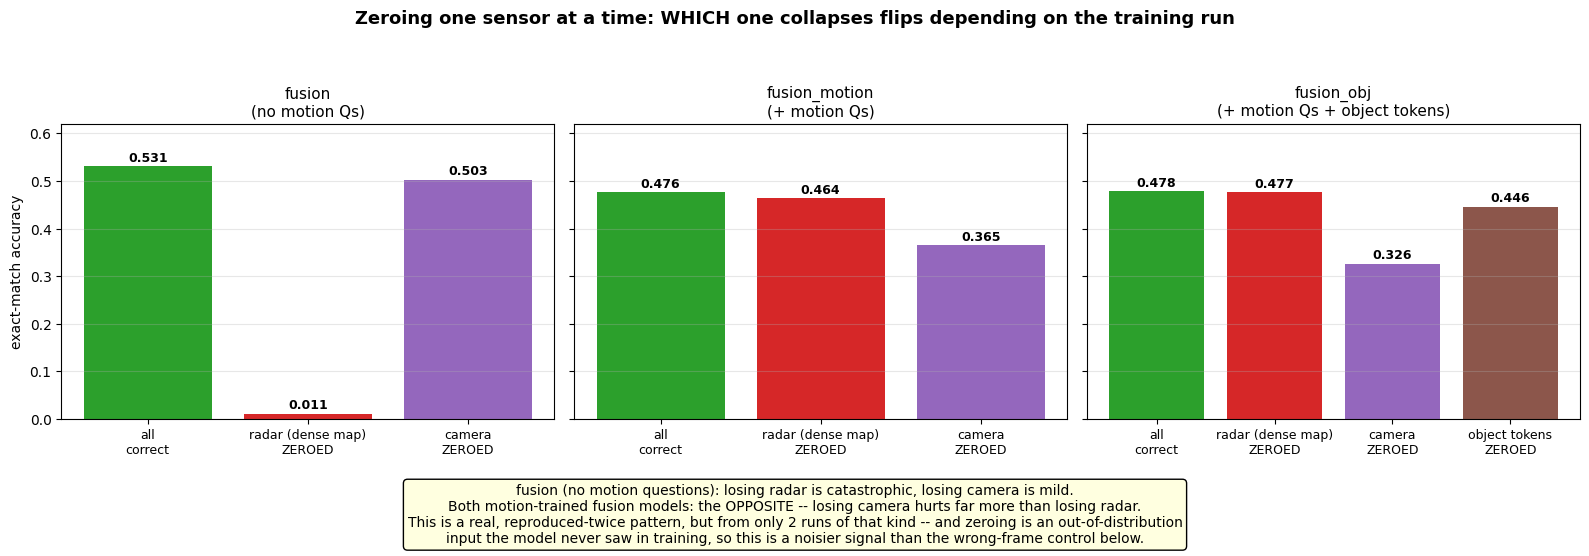

wrong-frame control (the more trustworthy, consistent signal) for the same three runs:
  fusion: correct 0.531 | wrong-frame 0.512 | gap +0.019
  fusion_motion: correct 0.476 | wrong-frame 0.470 | gap +0.007
  fusion_obj: correct 0.478 | wrong-frame 0.470 | gap +0.008


In [5]:
runs = ["fusion", "fusion_motion", "fusion_obj"]
run_labels = ["fusion\n(no motion Qs)", "fusion_motion\n(+ motion Qs)", "fusion_obj\n(+ motion Qs + object tokens)"]
mod_label = {"feats": "radar (dense map)", "cam_feats": "camera", "motion_feats": "object tokens"}
mod_color = {"feats": "tab:red", "cam_feats": "tab:purple", "motion_feats": "tab:brown"}

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), sharey=True)
for ax, name, label in zip(axes, runs, run_labels):
    row = R[name]
    correct = row["correct"]["acc"]
    mods = list(row["zeroed"])
    labels = ["all\ncorrect"] + [f"{mod_label[m]}\nZEROED" for m in mods]
    vals = [correct] + [row["zeroed"][m]["acc"] for m in mods]
    colors = ["tab:green"] + [mod_color[m] for m in mods]
    ax.bar(range(len(vals)), vals, color=colors)
    for i, v in enumerate(vals):
        ax.text(i, v + 0.01, f"{v:.3f}", ha="center", fontsize=9, fontweight="bold")
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, fontsize=9)
    ax.set_title(label, fontsize=11)
    ax.grid(alpha=0.3, axis="y")
axes[0].set_ylabel("exact-match accuracy")
axes[0].set_ylim(0, 0.62)
fig.suptitle("Zeroing one sensor at a time: WHICH one collapses flips depending on the training run", fontsize=13, fontweight="bold")
fig.text(0.5, 0.01,
          "fusion (no motion questions): losing radar is catastrophic, losing camera is mild.\n"
          "Both motion-trained fusion models: the OPPOSITE -- losing camera hurts far more than losing radar.\n"
          "This is a real, reproduced-twice pattern, but from only 2 runs of that kind -- and zeroing is an out-of-distribution\n"
          "input the model never saw in training, so this is a noisier signal than the wrong-frame control below.",
          ha="center", fontsize=10, bbox=dict(boxstyle="round", fc="lightyellow", ec="k"))
plt.tight_layout(rect=[0, 0.14, 1, 0.93])
plt.show()

print("wrong-frame control (the more trustworthy, consistent signal) for the same three runs:")
for name in runs:
    row = R[name]
    print(f"  {name}: correct {row['correct']['acc']:.3f} | wrong-frame {row['wrong_frame']['acc']:.3f} | gap {row['correct']['acc'] - row['wrong_frame']['acc']:+.3f}")

## Summary and what's next

**What worked:**
- Adding camera tokens: fusion is the best model AND shows the clearest sign yet of reading real sensor content
  (biggest correct-vs-wrong-frame gap of any model trained so far).
- Explicit per-object motion tokens gave a real, if modest, win: `radar_obj` scored best of all seven models on
  "how many cars are moving?", and `fusion_obj` scored best on "how many pedestrians are moving?" -- both clearing
  the majority-vote baseline, which nothing did on the dense-map-only pass.
- The infrastructure -- three independent, swappable token streams (radar / camera / explicit objects), with
  per-modality wrong-frame AND zeroing controls -- is now in place and reusable at any data scale.

**What didn't work (yet), stated honestly:**
- The speed-bucket question ("slow or fast?") was not improved by ANY model, dense-map or explicit-object-token,
  and the object-tokens-alone model did noticeably WORSE than guessing on it.
- The zeroing ablation (blank one sensor to zero, keep the others correct) gave an inconsistent answer to "which
  sensor matters most": the original fusion model collapsed when radar was zeroed and barely noticed camera being
  zeroed; both motion-trained fusion models showed the exact opposite. Zeroing is an out-of-distribution input the
  model never trained on, so part of what it measures is brittleness, not clean sensor reliance -- the wrong-frame
  control (a real, just wrong, frame) stayed the more consistent signal throughout.
- Along the way, a real bug was caught and fixed: six of the eleven trained models were initially re-evaluated on the
  wrong question set (missing the motion questions) because their saved config files predated a field added mid-run.
  Caught via a sanity check against the original training logs before any numbers went into this notebook.

**Deliberately not done in this pass** (scoped out to keep this increment reviewable):
- A learned trust-gate that reweights camera vs. radar by scene condition (day/night/rain) -- the next architecture
  piece once there's more data to validate it against.
- The real day/night condition-split evaluation (the paper's actual headline claim) -- nuScenes-mini's `mini_val`
  split happens to contain zero night keyframes (all 3 night scenes landed in `mini_train`), so this needs either a
  custom mini re-split (code-validation only) or, properly, the trainval-scale data.

**Recommended next step:** scale to nuScenes trainval (Phase C). The motion-question results in this notebook are the
strongest argument for it yet -- they show a real signal exists (radar_obj's and fusion_obj's wins) but is too weak
and noisy on 6 scenes' worth of data to draw a firm conclusion either way.